# Replicação do artigo "Pick and Choose" (PC-GNN) — YelpChi e Amazon (v3)

Disciplina de Detecção de Intrusão. Este notebook replica o experimento principal de
Liu et al., *Pick and Choose: A GNN-based Imbalanced Learning Approach for Fraud Detection* (WWW 2021):
a linha **PC-GNN** da Tabela 3 (F1-macro, AUC, G-Mean) e o F1 por classe da Tabela 5, em YelpChi e Amazon.

**O que ele faz**
1. Clona o código dos autores (`Fialhoalves/PC-GNN`) sem alterá-lo.
2. Obtém os dados de **três experimentos** e confere cada um com a Tabela 1 do artigo:
   - `yelp100`: YelpChi com **100 features**, a dimensão que o artigo reporta (versão antiga do dataset, do repositório DGFraud);
   - `yelp`: YelpChi com 32 features (versão pública do CARE-GNN);
   - `amazon`: Amazon com 25 features (CARE-GNN).
3. Gera as listas de adjacência. O `data_process.py` original tem a parte da Amazon comentada, então isso é feito aqui, reutilizando a mesma função `sparse_to_adjlist` do repositório.
4. Treina o PC-GNN com várias seeds em cada experimento, usando os YAML dos autores.
5. Mostra média ± desvio padrão ao lado dos números do artigo e compara o YelpChi com 32 × 100 features, seed a seed.

**O que ele NÃO cobre:** os baselines (GCN, GAT, GraphSAINT, CARE-GNN...) e as ablações PC-GNN\P e PC-GNN\C.
O repositório implementa apenas o PC-GNN e versões simples de GraphSAGE e GCN.

Execute de cima para baixo. Os resultados de cada seed são gravados no Drive, então uma sessão interrompida retoma de onde parou.

**Histórico de versões**
- **v1**: primeira versão (YelpChi 32 features e Amazon 25 features, dados do Drive ou do CARE-GNN).
- **v2**: os arquivos do seu Drive passaram a ter prioridade; resultados salvos só são reaproveitados se o SHA-256 dos dados for o mesmo; avisos do scipy silenciados.
- **v3**: novo experimento `yelp100` (YelpChi com 100 features, como no artigo). Cada experimento usa a sua própria pasta de dados, indicada ao `main.py` pelo campo `data_dir` do YAML, então o `data/` do repositório nunca é sobrescrito. O grafo de cada arquivo é conferido por uma impressão digital (SHA-256 da estrutura), e há uma comparação pareada 32 × 100 features. Os resultados de `yelp` e `amazon` da v1/v2 continuam válidos e são reaproveitados se `RESULTS_ROOT` for o mesmo.

## 1. Controles

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import math
import os
import platform
import re
import shutil
import subprocess
import sys
import time
import warnings
from urllib.request import urlretrieve
from zipfile import ZipFile

# ---------- O que executar ----------
# 'yelp100' = YelpChi 100 features (DGFraud) | 'yelp' = YelpChi 32 features (CARE-GNN) | 'amazon' = Amazon 25 features (CARE-GNN)
# Com o mesmo RESULTS_ROOT da v1/v2, as seeds já concluídas de 'yelp' e 'amazon' são puladas; só 'yelp100' treina.
DATASETS = ['yelp100', 'yelp', 'amazon']
SEEDS = [42, 448, 854, 29493, 88867, 72, 123, 2024, 31337, 7]    # 10 execuções, como no artigo (as 5 primeiras são as do YAML do repositório)
NUM_EPOCHS = None        # None = usa o YAML do repositório (51 épocas). O texto do artigo cita 100 épocas.
QUICK_TEST = False       # True = 1 seed e 6 épocas, só para testar o notebook (resultados vão para uma subpasta)

# ---------- Repositório e dados ----------
REPO_URL = 'https://github.com/Fialhoalves/PC-GNN.git'
REPO_REF = 'main'
REPO = Path('/content/PC-GNN')
USE_DRIVE = True
DATA_DRIVE_DIR = Path('/content/drive/MyDrive/PC_GNN_data')      # pasta no Drive com YelpChi.mat / Amazon.mat / YelpChi_100d.mat (ou os .zip). O que não estiver lá é baixado.
DATA_WORK = Path('/content/pcgnn_data')                          # cópia de trabalho dos dados (uma subpasta por experimento), fora do repositório
RESULTS_ROOT = Path('/content/drive/MyDrive/PC_GNN_replicacao')  # onde resultados, logs e checkpoints ficam guardados

# O scipy emite avisos de depreciação a cada loadmat; não afetam o resultado e poluem a saída.
warnings.filterwarnings('ignore', category=DeprecationWarning)
os.environ['PYTHONWARNINGS'] = 'ignore::DeprecationWarning'   # idem nos subprocessos (pré-processamento e main.py)

assert DATASETS and set(DATASETS) <= {'yelp100', 'yelp', 'amazon'} and len(set(DATASETS)) == len(DATASETS), \
    "DATASETS deve conter, sem repetir, 'yelp100', 'yelp' e/ou 'amazon'."
assert len(SEEDS) == len(set(SEEDS)) and len(SEEDS) >= 2, 'Use pelo menos 2 seeds distintas.'

## 2. Ambiente e Drive
Usa o PyTorch que já vem no Colab. **Não instale o `requirements.txt` do repositório** (pede `torch==1.4.0` e `networkx<=1.11`, que não funcionam no Colab atual e o código nem usa networkx).
O treino roda em CPU, como nos seus experimentos anteriores: o gargalo é o laço Python de amostragem de vizinhos, não a multiplicação de matrizes.

In [ ]:
import importlib
import importlib.metadata

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if USE_DRIVE and IN_COLAB:
    drive.mount('/content/drive')
    if not Path('/content/drive/MyDrive').is_dir():
        raise RuntimeError('Drive indisponível; confira a conta Google e a montagem.')
else:
    USE_DRIVE = False
    DATA_DRIVE_DIR = None
    RESULTS_ROOT = Path('/content/PC_GNN_replicacao')

if QUICK_TEST:
    SEEDS = SEEDS[:1]
    NUM_EPOCHS = 6
    RESULTS_ROOT = RESULTS_ROOT / 'quick_test'
RESULTS_ROOT.mkdir(parents=True, exist_ok=True)

PACKAGES = {'numpy': 'numpy', 'scipy': 'scipy', 'sklearn': 'scikit-learn', 'torch': 'torch',
            'yaml': 'PyYAML', 'pandas': 'pandas', 'matplotlib': 'matplotlib'}
VERSIONS = {}
for module, package in PACKAGES.items():
    importlib.import_module(module)
    VERSIONS[package] = importlib.metadata.version(package)

import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
import scipy.sparse as sp
import torch
from scipy.io import loadmat
try:
    from IPython.display import display
except ImportError:
    display = print

print('Python', sys.version.split()[0], '|', platform.platform())
print(json.dumps(VERSIONS, indent=2))
print('GPU visível:', torch.cuda.is_available(), '(o treino usa CPU de propósito)')
print('Resultados em:', RESULTS_ROOT)
print('Experimentos:', DATASETS)
print('Seeds:', SEEDS, '| épocas:', NUM_EPOCHS or 'as do YAML do repositório')

Mounted at /content/drive
Python 3.13.18 | Linux-6.6.159+-x86_64-with-glibc2.39
{
  "numpy": "2.4.6",
  "scipy": "1.16.3",
  "scikit-learn": "1.6.1",
  "torch": "2.11.0+cpu",
  "PyYAML": "6.0.3",
  "pandas": "2.2.3",
  "matplotlib": "3.10.0"
}
GPU visível: False (o treino usa CPU de propósito)
Resultados em: /content/drive/MyDrive/PC_GNN_replicacao
Experimentos: ['yelp100', 'yelp', 'amazon']
Seeds: [42, 448, 854, 29493, 88867, 72, 123, 2024, 31337, 7] | épocas: as do YAML do repositório


## 3. Código dos autores
Clona o repositório se ele ainda não existir. Um clone existente **não** recebe pull nem reset. O commit usado fica registrado nos resultados.

In [ ]:
if not (REPO / 'main.py').is_file():
    if REPO.exists() and any(REPO.iterdir()):
        raise RuntimeError(f'{REPO} existe mas não parece ser o clone do PC-GNN. Nada foi apagado; confira REPO.')
    subprocess.run(['git', 'clone', '--branch', REPO_REF, REPO_URL, str(REPO)], check=True)


def git(*args):
    return subprocess.run(['git', *args], cwd=REPO, capture_output=True, text=True).stdout.strip()


COMMIT = git('rev-parse', 'HEAD')
LOCAL_CHANGES = git('status', '--porcelain', '--', 'main.py', 'src', 'config')
required = ['main.py', 'src/model_handler.py', 'src/utils.py', 'src/layers.py',
            'config/pcgnn_yelpchi.yml', 'config/pcgnn_amazon.yml']
missing = [name for name in required if not (REPO / name).is_file()]
if missing:
    raise FileNotFoundError(f'Arquivos ausentes no clone: {missing}')
print('Commit:', COMMIT)
print('Alterações locais em main.py/src/config:', LOCAL_CHANGES or 'nenhuma')

Commit: 9d7d7fae491081178b6e12e193fb89cfc330f2be
Alterações locais em main.py/src/config: nenhuma


## 4. Datasets
Cada experimento tem uma pasta de trabalho própria, `DATA_WORK/<experimento>/`, e o treino aponta para ela pelo campo `data_dir` do YAML. O `data/` do repositório não é modificado. Para cada experimento o notebook procura o arquivo nesta ordem:
1. `DATA_DRIVE_DIR` no seu Drive (aceita `.mat` ou `.zip`; **tem prioridade**). Nomes esperados: `YelpChi.mat`, `Amazon.mat` e `YelpChi_100d.mat`;
2. a cópia de trabalho que já existe nesta sessão;
3. `data/` do repositório (só `yelp` e `amazon`);
4. download: CARE-GNN (`yelp`, `amazon`) ou DGFraud (`yelp100`).

A coluna `sha256 (12)` identifica o arquivo usado e `arquivo de referência` diz se ele é o arquivo conhecido de cada experimento (`fedb35a8fa53` para YelpChi 32 features, `4b7e3f9cccc6` para Amazon e `183d8d58d55b` para YelpChi 100 features). Resultados salvos só são reaproveitados se o SHA-256 dos dados for o mesmo.

A tabela confere cada arquivo com a **Tabela 1 do artigo** (nós, arestas, IR, arestas por relação, dimensão das features). Além disso, uma **impressão digital do grafo** (SHA-256 da estrutura das matrizes de adjacência e dos rótulos, sem as features) é comparada com a do grafo de referência do CARE-GNN. Assim o notebook confirma sozinho que `yelp` e `yelp100` têm o mesmo grafo e os mesmos rótulos, e que a única diferença entre eles são as features.

### De onde vem o YelpChi de 100 features (`yelp100`)
- O artigo reporta **100 dimensões** de features para o YelpChi. O arquivo público do CARE-GNN tem 32. O README do PC-GNN diz que os resultados do artigo foram obtidos com a versão **antiga** do YelpChi.
- Essa versão antiga está no histórico do repositório `safe-graph/DGFraud`: commit `9446e3464ddcffe86b7f8338c738f24b64eff164` (2020-06-24, mensagem "Update YelpChi.zip"), arquivo `dataset/YelpChi.zip`. O notebook baixa exatamente esse commit e confere o SHA-256 do zip antes de usá-lo.
- **Verificado** (em 06/11/2026, fora do notebook, e dentro dele pela impressão digital do grafo): mesmos 45.954 nós, mesmas três relações (R-U-R 49.315, R-T-R 573.616 e R-S-R 3.402.743 arestas) e mesmos rótulos do arquivo de 32 features. A diferença são as features: 45954×100, inteiros de 0 a 94 (contagens), contra 45954×32 com valores entre 0 e 1. O código dos autores normaliza as features por linha antes de treinar (`normalize` em `model_handler.py`), então a escala diferente não é problema. 64 revisões (0,14%) têm todas as features zeradas; nenhuma coluna é toda zero.
- O arquivo **não traz a matriz `homo`**. Ela é reconstruída como a união das três relações, e o resultado tem exatamente a mesma estrutura do `homo` do arquivo público (7.693.958 entradas, o que dá as 3.846.979 arestas da Tabela 1).
- **Não está provado** que este arquivo seja exatamente o usado pelos autores: o artigo não dá hash nem descreve cada feature. Outras versões antigas no histórico do DGFraud não abrem com `scipy.io.loadmat` e não foram usadas.
- **Amazon:** não foi encontrada versão com 100 features. Todas as fontes consultadas descrevem 25. O "100" que o artigo cita para a Amazon pode ser um erro de redação, mas isso não foi verificado; por isso a Amazon só roda com 25 features.

In [ ]:
EXPERIMENTS = {
    'yelp':    dict(base='yelp',   name='YelpChi (32 feat.)',  stem='YelpChi',      mat='YelpChi.mat', source='care'),
    'yelp100': dict(base='yelp',   name='YelpChi (100 feat.)', stem='YelpChi_100d', mat='YelpChi.mat', source='dgfraud'),
    'amazon':  dict(base='amazon', name='Amazon (25 feat.)',   stem='Amazon',       mat='Amazon.mat',  source='care'),
}
# 'graph_sha256' = impressão digital do grafo de referência (CARE-GNN): homo + 3 relações + rótulos, só a estrutura.
GRAPH = {
    'yelp': dict(keys=['net_rur', 'net_rtr', 'net_rsr', 'features', 'label'],
                 relations=[('R-U-R', 'net_rur', 49315), ('R-T-R', 'net_rtr', 573616), ('R-S-R', 'net_rsr', 3402743)],
                 paper=dict(nodes=45954, edges=3846979, ir=5.9, dim=100),
                 graph_sha256='413b1f841feb846eea2f56682f1d73fe08bf3291af975949ae8807c0814b77ae'),
    'amazon': dict(keys=['net_upu', 'net_usu', 'net_uvu', 'features', 'label'],
                   relations=[('U-P-U', 'net_upu', 175608), ('U-S-U', 'net_usu', 3566479), ('U-V-U', 'net_uvu', 1036737)],
                   paper=dict(nodes=11944, edges=4398392, ir=13.5, dim=100),
                   graph_sha256='d184511885e0b8653faa08121011085163da7aa873402797c7573dbd24a2d58a'),
}
REFERENCE_SHA12 = {'yelp': 'fedb35a8fa53', 'yelp100': '183d8d58d55b', 'amazon': '4b7e3f9cccc6'}
CARE_GNN_URL = 'https://raw.githubusercontent.com/YingtongDou/CARE-GNN/master/data/{}.zip'
DGFRAUD_COMMIT = '9446e3464ddcffe86b7f8338c738f24b64eff164'
DGFRAUD_URL = f'https://raw.githubusercontent.com/safe-graph/DGFraud/{DGFRAUD_COMMIT}/dataset/YelpChi.zip'
DGFRAUD_ZIP_SHA256 = 'b284e8af073c6e0bf9f3d49e9c8810059512b574ca291d890e13d0ad3cd2d3ce'


def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as source:
        for block in iter(lambda: source.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()


def extract_mat(zip_path, target):
    with ZipFile(zip_path) as archive:
        members = [name for name in archive.namelist() if Path(name).name.lower() == target.name.lower()]
        if len(members) != 1:
            raise ValueError(f'{zip_path} deve conter exatamente um {target.name}.')
        part = target.with_name(target.name + '.part')
        with archive.open(members[0]) as source, part.open('wb') as out:
            shutil.copyfileobj(source, out)
        part.replace(target)


def obtain_mat(key):
    exp = EXPERIMENTS[key]
    target = DATA_WORK / key / exp['mat']
    target.parent.mkdir(parents=True, exist_ok=True)
    if DATA_DRIVE_DIR is not None and DATA_DRIVE_DIR.is_dir():       # os seus arquivos têm prioridade
        files = sorted(p for p in DATA_DRIVE_DIR.rglob('*') if p.is_file())
        mats = [p for p in files if p.name.lower() == f"{exp['stem']}.mat".lower()]
        zips = [p for p in files if p.name.lower() == f"{exp['stem']}.zip".lower()]
        if len(mats) + len(zips) > 1:
            print(f"[{key}] atenção: mais de um arquivo '{exp['stem']}' no Drive; usando {(mats + zips)[0]}")
        if mats:
            if not target.is_file() or sha256_file(target) != sha256_file(mats[0]):
                shutil.copyfile(mats[0], target)
            return target, f'Drive: {mats[0]}'
        if zips:
            extract_mat(zips[0], target)
            return target, f'Drive (zip): {zips[0]}'
    if target.is_file():
        return target, 'cópia de trabalho já existente nesta sessão'
    repo_copy = REPO / 'data' / exp['mat']
    if exp['source'] == 'care' and repo_copy.is_file():
        shutil.copyfile(repo_copy, target)
        return target, 'data/ do repositório'
    archive_path = target.parent / f"{exp['stem']}.download.zip"
    if exp['source'] == 'care':
        print(f'{key}: não encontrado; baixando do CARE-GNN...')
        urlretrieve(CARE_GNN_URL.format(exp['stem']), archive_path)
        origin = 'download CARE-GNN'
    else:
        print(f'{key}: não encontrado; baixando do DGFraud (commit {DGFRAUD_COMMIT[:7]})...')
        urlretrieve(DGFRAUD_URL, archive_path)
        if sha256_file(archive_path) != DGFRAUD_ZIP_SHA256:
            archive_path.unlink()
            raise RuntimeError('O zip baixado do DGFraud não tem o SHA-256 esperado. Nada foi usado.')
        origin = f'download DGFraud, commit {DGFRAUD_COMMIT[:7]} (zip conferido por SHA-256)'
    extract_mat(archive_path, target)
    archive_path.unlink()
    return target, origin


def union_of(matrices):
    """União (estrutura) de matrizes de adjacência. Usada para reconstruir o `homo` que o .mat do DGFraud não traz."""
    result = matrices[0].tocsr().copy()
    for other in matrices[1:]:
        result = result + other.tocsr()
    result = result.tocsr()
    result.data[:] = 1
    return result


def graph_fingerprint(matrices, labels):
    """SHA-256 da estrutura (índices) das matrizes e dos rótulos; ignora features e valores das arestas."""
    digest = hashlib.sha256()
    for matrix in matrices:
        matrix = sp.csr_matrix(matrix).copy()
        matrix.eliminate_zeros()
        matrix.sum_duplicates()
        matrix.sort_indices()
        digest.update(np.asarray(matrix.shape, dtype=np.int64).tobytes())
        digest.update(np.asarray(matrix.indptr, dtype=np.int64).tobytes())
        digest.update(np.asarray(matrix.indices, dtype=np.int64).tobytes())
    digest.update(np.asarray(labels, dtype=np.int64).ravel().tobytes())
    return digest.hexdigest()


DATA_INFO = {}
rows = []
for key in DATASETS:
    exp = EXPERIMENTS[key]
    spec = GRAPH[exp['base']]
    path, origin = obtain_mat(key)
    mat = loadmat(path)
    needed = spec['keys'] + (['homo'] if exp['source'] == 'care' else [])      # o .mat do DGFraud não traz 'homo'
    absent = [name for name in needed if name not in mat]
    if absent:
        raise KeyError(f'{path.name} ({key}) sem as chaves {absent}. Este não é o arquivo esperado pelo repositório.')
    relation_keys = [name for _, name, _ in spec['relations']]
    if 'homo' in mat:
        homo, homo_source = mat['homo'], 'no .mat'
    else:
        homo, homo_source = union_of([mat[name] for name in relation_keys]), 'reconstruído (união das 3 relações)'
    labels = np.asarray(mat['label']).ravel()
    positives = int(labels.sum())
    digest = sha256_file(path)
    graph_sha = graph_fingerprint([homo] + [mat[name] for name in relation_keys], labels)
    row = {'experimento': key, 'origem': origin, 'sha256 (12)': digest[:12],
           'arquivo de referência': 'sim' if digest[:12] == REFERENCE_SHA12[key] else 'não',
           'nós': len(labels), 'features': mat['features'].shape[1], 'fraudes': positives,
           'IR': round((len(labels) - positives) / positives, 1), 'arestas (homo)': int(homo.nnz // 2)}
    for name, name_key, _ in spec['relations']:
        row[name] = int(mat[name_key].nnz // 2)
    rows.append(row)
    paper = spec['paper']
    notes = []
    if len(labels) != paper['nodes']:
        notes.append(f"nós {len(labels)} != {paper['nodes']} (Tabela 1)")
    if row['arestas (homo)'] != paper['edges']:
        notes.append(f"arestas {row['arestas (homo)']} != {paper['edges']} (Tabela 1)")
    for name, _, expected in spec['relations']:
        if row[name] != expected:
            notes.append(f'{name}: {row[name]} != {expected} (Tabela 1)')
    if row['IR'] != paper['ir']:
        notes.append(f"IR {row['IR']} != {paper['ir']} (Tabela 1)")
    if row['features'] != paper['dim']:
        notes.append(f"features = {row['features']}, o artigo reporta {paper['dim']}")
    DATA_INFO[key] = {'experiment': key, 'name': exp['name'], 'base': exp['base'], 'file': path.name, 'path': str(path),
                      'sha256': digest, 'origin': origin, 'nodes': len(labels), 'feature_dim': int(mat['features'].shape[1]),
                      'positives': positives, 'graph_sha256': graph_sha, 'graph_matches_reference': graph_sha == spec['graph_sha256'],
                      'homo_source': homo_source, 'reference_file': digest[:12] == REFERENCE_SHA12[key],
                      'source_url': DGFRAUD_URL if exp['source'] == 'dgfraud' else CARE_GNN_URL.format(exp['stem']),
                      'divergences_from_paper': notes}
    del mat, homo, labels

display(pd.DataFrame(rows))
for key in DATASETS:
    info = DATA_INFO[key]
    graph_status = 'idêntico ao grafo de referência' if info['graph_matches_reference'] else 'DIFERE do grafo de referência (confira o arquivo!)'
    print(f"[{key}] grafo {graph_status} | homo: {info['homo_source']}")
    for note in info['divergences_from_paper']:
        print(f'      Tabela 1: {note}')

yelp100: não encontrado; baixando do DGFraud (commit 9446e34)...


,experimento,origem,sha256 (12),arquivo de referência,nós,features,fraudes,IR,arestas (homo),R-U-R,R-T-R,R-S-R,U-P-U,U-S-U,U-V-U
0,yelp100,"download DGFraud, commit 9446e34 (zip conferid...",183d8d58d55b,sim,45954,100,6677,5.9,3846979,49315.0,573616.0,3402743.0,NaN,NaN,NaN
1,yelp,Drive: /content/drive/MyDrive/PC_GNN_data/Yelp...,fedb35a8fa53,sim,45954,32,6677,5.9,3846979,49315.0,573616.0,3402743.0,NaN,NaN,NaN
2,amazon,Drive: /content/drive/MyDrive/PC_GNN_data/Amaz...,4b7e3f9cccc6,sim,11944,25,821,13.5,4398392,NaN,NaN,NaN,175608.0,3566479.0,1036737.0


[yelp100] grafo idêntico ao grafo de referência | homo: reconstruído (união das 3 relações)
[yelp] grafo idêntico ao grafo de referência | homo: no .mat
      Tabela 1: features = 32, o artigo reporta 100
[amazon] grafo idêntico ao grafo de referência | homo: no .mat
      Tabela 1: features = 25, o artigo reporta 100


## 5. Listas de adjacência
O PC-GNN lê grafos de arquivos `*_adjlists.pickle` que ficam na pasta de dados do experimento. Para o YelpChi, é o que `src/data_process.py` faz. Para a Amazon, esse trecho está comentado no repositório, então um script auxiliar (fora do repositório) aplica a **mesma** função `sparse_to_adjlist` às três relações e ao `homo`, com os nomes de arquivo que `load_data` espera (`amz_*_adjlists.pickle`). Cada arquivo inclui self-loops, como no original. Para `yelp100`, que não traz `homo`, o script usa a união das três relações.
Se os pickles da pasta já correspondem ao mesmo grafo (mesma impressão digital), não são refeitos. Se outro experimento com o mesmo grafo (`yelp` e `yelp100`) já os tem, eles são copiados em vez de gerados de novo. Esta etapa usa bastante RAM e leva de 1 a 3 minutos por grafo.

In [ ]:
PREP_SCRIPT = '''
import sys
from pathlib import Path
from scipy.io import loadmat

repo, base, data_dir = Path(sys.argv[1]), sys.argv[2], Path(sys.argv[3])
sys.path.insert(0, str(repo / 'src'))
from utils import sparse_to_adjlist   # a mesma função que src/data_process.py usa

SPEC = {
    'yelp':   ('YelpChi.mat', 'yelp', {'rur': 'net_rur', 'rtr': 'net_rtr', 'rsr': 'net_rsr'}),
    'amazon': ('Amazon.mat',  'amz',  {'upu': 'net_upu', 'usu': 'net_usu', 'uvu': 'net_uvu'}),
}
filename, prefix, relations = SPEC[base]
mat = loadmat(data_dir / filename)
keys = list(relations.values())
if 'homo' in mat:
    homo = mat['homo']
else:   # o .mat do DGFraud não traz 'homo': usa a união das relações
    homo = mat[keys[0]] + mat[keys[1]] + mat[keys[2]]
for name, key in relations.items():
    out = data_dir / f'{prefix}_{name}_adjlists.pickle'
    sparse_to_adjlist(mat[key], str(out))
    print('gerado', out.name, flush=True)
out = data_dir / f'{prefix}_homo_adjlists.pickle'
sparse_to_adjlist(homo, str(out))
print('gerado', out.name, flush=True)
'''
PREP_PATH = Path('/content/prep_adjlists.py')
PREP_PATH.parent.mkdir(exist_ok=True)
PREP_PATH.write_text(PREP_SCRIPT, encoding='utf-8')

ADJ_NAMES = {'yelp': [f'yelp_{r}_adjlists.pickle' for r in ('rur', 'rtr', 'rsr', 'homo')],
             'amazon': [f'amz_{r}_adjlists.pickle' for r in ('upu', 'usu', 'uvu', 'homo')]}
STAMP_NAME = 'adjlists.stamp.json'


def adjlists_fresh(key):
    """Os pickles da pasta do experimento existem e foram gerados para o mesmo grafo?"""
    data_dir = DATA_WORK / key
    paths = [data_dir / name for name in ADJ_NAMES[EXPERIMENTS[key]['base']]]
    stamp = data_dir / STAMP_NAME
    if not (stamp.is_file() and all(p.is_file() and p.stat().st_size > 0 for p in paths)):
        return False
    try:
        return json.loads(stamp.read_text())['graph_sha256'] == DATA_INFO[key]['graph_sha256']
    except (ValueError, KeyError, OSError):
        return False


for key in DATASETS:
    base = EXPERIMENTS[key]['base']
    data_dir = DATA_WORK / key
    if adjlists_fresh(key):
        print(f'{key}: listas de adjacência já geradas para este grafo.')
        continue
    sibling = next((other for other in DATASETS if other != key and DATA_INFO[other]['base'] == base
                    and DATA_INFO[other]['graph_sha256'] == DATA_INFO[key]['graph_sha256'] and adjlists_fresh(other)), None)
    if sibling is not None:
        for name in ADJ_NAMES[base]:
            shutil.copyfile(DATA_WORK / sibling / name, data_dir / name)
        (data_dir / STAMP_NAME).write_text(json.dumps({'graph_sha256': DATA_INFO[key]['graph_sha256']}), encoding='utf-8')
        print(f'{key}: mesmo grafo de {sibling}; listas de adjacência copiadas.')
        continue
    print(f'{key}: gerando listas de adjacência (aguarde)...')
    started = time.time()
    subprocess.run([sys.executable, '-u', str(PREP_PATH), str(REPO), base, str(data_dir)], check=True)
    paths = [data_dir / name for name in ADJ_NAMES[base]]
    assert all(p.is_file() and p.stat().st_size > 0 for p in paths), 'Algum pickle não foi gerado.'
    (data_dir / STAMP_NAME).write_text(json.dumps({'graph_sha256': DATA_INFO[key]['graph_sha256']}), encoding='utf-8')
    print(f'{key}: pronto em {time.time() - started:.0f}s')

yelp100: gerando listas de adjacência (aguarde)...
yelp100: pronto em 80s
yelp: mesmo grafo de yelp100; listas de adjacência copiadas.
amazon: gerando listas de adjacência (aguarde)...
amazon: pronto em 96s


## 6. Hiperparâmetros: YAML do repositório × artigo
O treino usa os YAML dos autores (`config/pcgnn_yelpchi.yml` e `config/pcgnn_amazon.yml`), alterando apenas `seed`, `save_dir`, `data_dir` (a pasta de dados do experimento), `no_cuda=True` e, se pedido, `num_epochs`. `yelp` e `yelp100` usam exatamente o mesmo YAML.
Diferenças a observar: o artigo cita 100 épocas e o YAML tem 51; para a Amazon o YAML usa `lr=0.005`, `weight_decay=0.0005`, `batch_size=256` e `thres=0.4`, enquanto o texto do artigo descreve um único `lr=0.01` e `N_batch=1024`. O código dos autores é a fonte mais direta do que foi executado, então ele é o padrão aqui. Para testar as 100 épocas, defina `NUM_EPOCHS = 100` nos controles.

In [ ]:
REPO_CONFIG = {'yelp': 'pcgnn_yelpchi.yml', 'amazon': 'pcgnn_amazon.yml'}
PAPER_SETTINGS = {'lr': 0.01, 'emb_size': 64, 'alpha': 2, 'batch_size': 1024, 'num_epochs': 100}


def make_config(key, seed, run_dir):
    base = EXPERIMENTS[key]['base']
    config = yaml.safe_load((REPO / 'config' / REPO_CONFIG[base]).read_text(encoding='utf-8'))
    if config.get('data_name') != base or config.get('model') != 'PCGNN':
        raise ValueError(f'YAML inesperado para {key}: {config.get("data_name")}/{config.get("model")}')
    if any(isinstance(value, list) for value in config.values()):
        raise ValueError('O YAML tem hiperparâmetros em lista; este notebook roda uma configuração por vez.')
    config['seed'] = seed
    config['no_cuda'] = True
    config['data_dir'] = str(DATA_WORK / key) + '/'          # load_data concatena o nome do arquivo direto neste texto
    config['save_dir'] = str(run_dir / 'checkpoints') + '/'   # main.py concatena o timestamp direto neste texto
    if NUM_EPOCHS is not None:
        config['num_epochs'] = NUM_EPOCHS
    return config


def semantic(config):
    """Só os hiperparâmetros: os caminhos mudam de sessão para sessão e não afetam o resultado."""
    return {name: value for name, value in config.items() if name not in ('save_dir', 'data_dir')}


PARAMS = ['lr', 'weight_decay', 'batch_size', 'num_epochs', 'valid_epochs', 'emb_size', 'alpha', 'rho', 'thres', 'train_ratio', 'test_ratio']
table = {}
for base, title in (('yelp', 'YelpChi'), ('amazon', 'Amazon')):
    key = next((k for k in DATASETS if EXPERIMENTS[k]['base'] == base), None)
    if key is not None:
        cfg = make_config(key, SEEDS[0], RESULTS_ROOT / key / 'seed_x')
        table[f'{title} (executado)'] = [str(cfg.get(name)) for name in PARAMS]
table['artigo (texto)'] = [str(PAPER_SETTINGS.get(name, '—')) for name in PARAMS]
display(pd.DataFrame(table, index=PARAMS))

,YelpChi (executado),Amazon (executado),artigo (texto)
lr,0.01,0.005,0.01
weight_decay,0.001,0.0005,—
batch_size,1024,256,1024
num_epochs,51,51,100
valid_epochs,5,5,—
emb_size,64,64,64
alpha,2,2,2
rho,0.5,0.5,—
thres,0.5,0.4,—
train_ratio,0.4,0.4,—


## 7. Executor por seed
`main.py` não tem argumento `--seed`; a seed vai no YAML da execução. Cada execução tem pasta própria em `RESULTS_ROOT/<experimento>/seed_<n>/` com `config.yml`, `train.log`, checkpoints e `result.json`.
Se `result.json` já existe com a mesma configuração e os mesmos dados, a seed é pulada (retomada). Se a configuração ou o SHA-256 dos dados mudou, o notebook para em vez de misturar resultados incomparáveis: use outro `RESULTS_ROOT` ou apague a pasta daquela seed. Antes de cada treino o notebook confere de novo o SHA-256 do arquivo de dados e, depois, que a dimensão das features impressa pelo `main.py` é a esperada.

O checkpoint testado é o da época com maior AUC de **validação**, como no código original. O teste só é avaliado uma vez, no fim. O campo `loss` impresso pelo código original não é uma média confiável da época (o acumulador é sobrescrito a cada batch), então não é usado para nada.

In [ ]:
NUM = r'([0-9.eE+-]+)'
TEST_LINE = re.compile(rf'GNN F1-binary-1:\s*{NUM}\s+F1-binary-0:\s*{NUM}\s+F1-macro:\s*{NUM}\s+G-Mean:\s*{NUM}\s+AUC:\s*{NUM}')
CONFUSION = re.compile(r'GNN TP:\s*(\d+)\s+TN:\s*(\d+)\s+FN:\s*(\d+)\s+FP:\s*(\d+)')
METRICS = ['f1_macro', 'auc', 'g_mean', 'f1_fraud', 'f1_benign']


def write_json(path, payload):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + '.tmp')
    temporary.write_text(json.dumps(payload, indent=2, ensure_ascii=False, allow_nan=False), encoding='utf-8')
    temporary.replace(path)


def parse_run(text):
    """Extrai o resultado de teste de uma execução completa de main.py."""
    result = {}
    for key, label in (('f1_macro', 'F1-Macro'), ('auc', 'AUC'), ('g_mean', 'G-Mean')):
        found = re.findall(rf'^{re.escape(label)}:[ \t]*(\S+)[ \t]*$', text, re.M)
        if len(found) != 1:
            raise ValueError(f'Resumo final ausente ou ambíguo: {label}')
        result[key] = float(found[0])
    restored = re.findall(r'^Restore model from epoch (\d+)[ \t]*$', text, re.M)
    paths = re.findall(r'^Model path:[ \t]*(.+)$', text, re.M)
    if len(restored) != 1 or len(paths) != 1:
        raise ValueError('Checkpoint de teste não identificado de forma única.')
    result['best_epoch'] = int(restored[0])
    result['checkpoint_path'] = paths[0].strip()
    test_section = text.split('Model path:', 1)[1]          # só o que vem depois da restauração é o teste
    lines = TEST_LINE.findall(test_section)
    if len(lines) != 1:
        raise ValueError('Linha de métricas do teste ausente ou ambígua.')
    f1_fraud, f1_benign, f1_macro, g_mean, auc = map(float, lines[0])
    for key, value in (('f1_macro', f1_macro), ('g_mean', g_mean), ('auc', auc)):
        if abs(value - result[key]) > 1e-4:
            raise ValueError(f'Resumo e linha de teste divergem em {key}: {result[key]} vs {value}')
    result.update(f1_fraud=f1_fraud, f1_benign=f1_benign)
    confusion = CONFUSION.findall(test_section)
    if len(confusion) == 1:
        result.update(zip(('tp', 'tn', 'fn', 'fp'), map(int, confusion[0])))
    for key in METRICS:
        value = result[key]
        if not math.isfinite(value) or not 0 <= value <= 1:
            raise ValueError(f'Métrica inválida: {key}={value}')
    dims = re.findall(r'^Feature dimension:[ \t]*(\d+)', text, re.M)
    result['feature_dim'] = int(dims[0]) if len(dims) == 1 else None
    split = re.findall(r'^Run on .+$', text, re.M)
    result['split_info'] = split[0] if split else None
    times = re.findall(r'^Epoch: \d+, loss: [^\n]+, time: ([0-9.eE+-]+)s$', text, re.M)
    result['train_seconds'] = float(sum(float(t) for t in times)) if times else None
    result['epochs_run'] = len(times)
    return result


def run_main(config_path, log_path, total_epochs):
    """Executa main.py, grava o log completo e mostra só as linhas principais."""
    after_restore = False
    with Path(log_path).open('w', encoding='utf-8') as log:
        with subprocess.Popen([sys.executable, '-u', 'main.py', '--config', str(config_path)], cwd=REPO,
                              stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
                              encoding='utf-8', errors='replace') as process:
            try:
                for line in process.stdout:
                    log.write(line)
                    log.flush()
                    shown = line.rstrip()
                    epoch = re.match(r'Epoch: (\d+),', shown)
                    if epoch and (int(epoch[1]) % 10 == 0 or int(epoch[1]) == total_epochs - 1):
                        print('   ', shown[:110], flush=True)
                    elif 'GNN F1-binary-1' in shown:
                        print('   ' + ('[teste] ' if after_restore else '[valid] ') + ' '.join(shown.split()), flush=True)
                    elif re.match(r'(Run on|Feature dimension|Restore model)', shown):
                        print('   ', shown, flush=True)
                    if shown.startswith('Restore model'):
                        after_restore = True
                returncode = process.wait()
            except BaseException:
                process.kill()
                process.wait()
                raise
    text = Path(log_path).read_text(encoding='utf-8')
    if returncode != 0:
        print('\n'.join(text.splitlines()[-25:]))
        raise RuntimeError(f'main.py terminou com código {returncode}. Log completo: {log_path}')
    return text


def check_data_ready(key):
    """Garante que o arquivo e os pickles que o main.py vai ler são os que a seção 4 conferiu."""
    info = DATA_INFO[key]
    path = Path(info['path'])
    if not path.is_file() or sha256_file(path) != info['sha256']:
        raise RuntimeError(f'{key}: o arquivo {path} mudou desde a seção 4. Reexecute as seções 4 e 5.')
    if not adjlists_fresh(key):
        raise RuntimeError(f'{key}: listas de adjacência ausentes ou de outro grafo. Reexecute a seção 5.')


def run_one(key, seed):
    run_dir = RESULTS_ROOT / key / f'seed_{seed}'
    config = make_config(key, seed, run_dir)
    result_path = run_dir / 'result.json'
    if result_path.is_file():
        record = json.loads(result_path.read_text(encoding='utf-8'))
        if semantic(record['config']) != semantic(config):
            raise ValueError(f'{key}, seed {seed}: configuração salva difere da atual. Use outro RESULTS_ROOT ou apague {run_dir}.')
        if record.get('data_sha256') != DATA_INFO[key]['sha256']:
            raise ValueError(f'{key}, seed {seed}: o resultado salvo foi gerado com outro arquivo de dados (SHA-256 diferente). '
                             f'Use outro RESULTS_ROOT para a série com estes dados ou apague {run_dir}.')
        print(f'{key}, seed {seed}: já concluída; pulando.')
        return record
    check_data_ready(key)
    run_dir.mkdir(parents=True, exist_ok=True)
    config_path = run_dir / 'config.yml'
    config_path.write_text(yaml.safe_dump(config, sort_keys=True), encoding='utf-8')
    print(f'{key}, seed {seed}: treinando ({config["num_epochs"]} épocas, dados: {DATA_INFO[key]["name"]})...')
    started = time.time()
    text = run_main(config_path, run_dir / 'train.log', config['num_epochs'])
    record = parse_run(text)
    if record['feature_dim'] != DATA_INFO[key]['feature_dim']:
        raise RuntimeError(f"{key}, seed {seed}: o main.py usou {record['feature_dim']} features, o esperado era {DATA_INFO[key]['feature_dim']}. "
                           'O resultado NÃO foi salvo. Confira data_dir.')
    record.update(dataset=key, experiment=key, seed=seed, config=config, commit=COMMIT, wall_seconds=time.time() - started,
                  data_sha256=DATA_INFO[key]['sha256'], graph_sha256=DATA_INFO[key]['graph_sha256'],
                  data_origin=DATA_INFO[key]['origin'], torch=VERSIONS['torch'], log_path=str(run_dir / 'train.log'))
    write_json(result_path, record)
    return record


def run_dataset(key):
    started = time.time()
    for position, seed in enumerate(SEEDS, 1):
        record = run_one(key, seed)
        elapsed = time.time() - started
        print(f'>> {key} {position}/{len(SEEDS)} seed {seed}: F1-macro {record["f1_macro"]:.4f} | AUC {record["auc"]:.4f} | '
              f'G-Mean {record["g_mean"]:.4f} | F1-fraude {record["f1_fraud"]:.4f}   (acumulado {elapsed / 60:.1f} min)\n')

## 8. Treino — YelpChi com 100 features (`yelp100`)
O experimento novo da v3. A estimativa de ~10 minutos por seed vem do YelpChi de 32 features; com a entrada maior, o tempo pode ser um pouco maior. Conte ~2 h para 10 seeds. Pode ser interrompido e retomado: seeds já concluídas são puladas.
Não execute dois treinos ao mesmo tempo na mesma sessão. Para um teste rápido do notebook inteiro, use `QUICK_TEST = True` nos controles.

In [ ]:
if 'yelp100' in DATASETS:
    run_dataset('yelp100')

yelp100, seed 42: treinando (51 épocas, dados: YelpChi (100 feat.))...
    Run on yelp, postive/total num: 6677/45954, train num 18381,valid num 9099, test num 18474, test positive num 2684
    Feature dimension: 100
    Epoch: 0, loss: 0.6815252304077148, time: 13.13663649559021s
   [valid] GNN F1-binary-1: 0.2735 F1-binary-0: 0.3504 F1-macro: 0.3120 G-Mean: 0.4386 AUC: 0.6374
   [valid] GNN F1-binary-1: 0.3180 F1-binary-0: 0.6620 F1-macro: 0.4900 G-Mean: 0.6129 AUC: 0.6704
    Epoch: 10, loss: 0.6236939827601115, time: 12.371096134185791s
   [valid] GNN F1-binary-1: 0.3272 F1-binary-0: 0.6886 F1-macro: 0.5079 G-Mean: 0.6264 AUC: 0.6832
   [valid] GNN F1-binary-1: 0.3456 F1-binary-0: 0.7240 F1-macro: 0.5348 G-Mean: 0.6484 AUC: 0.6986
    Epoch: 20, loss: 0.6407123406728109, time: 11.106299638748169s
   [valid] GNN F1-binary-1: 0.3327 F1-binary-0: 0.8004 F1-macro: 0.5665 G-Mean: 0.6165 AUC: 0.6788
   [valid] GNN F1-binary-1: 0.3119 F1-binary-0: 0.8424 F1-macro: 0.5771 G-Mean: 0.5664 AU

## 9. Treino — YelpChi com 32 features (`yelp`)
É a série da v1/v2. Com o mesmo `RESULTS_ROOT`, as seeds já concluídas são puladas em segundos (o SHA-256 dos dados e a configuração são conferidos). Em CPU de Colab, conte ~10 a 12 minutos por seed se for treinar do zero (nos seus experimentos anteriores com este YAML o treino levou ~9,5 min por seed).

In [ ]:
if 'yelp' in DATASETS:
    run_dataset('yelp')

yelp, seed 42: já concluída; pulando.
>> yelp 1/10 seed 42: F1-macro 0.5929 | AUC 0.8128 | G-Mean 0.7216 | F1-fraude 0.4149   (acumulado 0.0 min)

yelp, seed 448: já concluída; pulando.
>> yelp 2/10 seed 448: F1-macro 0.5771 | AUC 0.8196 | G-Mean 0.7165 | F1-fraude 0.4071   (acumulado 0.0 min)

yelp, seed 854: já concluída; pulando.
>> yelp 3/10 seed 854: F1-macro 0.6136 | AUC 0.8216 | G-Mean 0.7365 | F1-fraude 0.4336   (acumulado 0.0 min)

yelp, seed 29493: já concluída; pulando.
>> yelp 4/10 seed 29493: F1-macro 0.5951 | AUC 0.8109 | G-Mean 0.7225 | F1-fraude 0.4162   (acumulado 0.0 min)

yelp, seed 88867: já concluída; pulando.
>> yelp 5/10 seed 88867: F1-macro 0.6948 | AUC 0.8199 | G-Mean 0.6636 | F1-fraude 0.4793   (acumulado 0.0 min)

yelp, seed 72: já concluída; pulando.
>> yelp 6/10 seed 72: F1-macro 0.6719 | AUC 0.8176 | G-Mean 0.7330 | F1-fraude 0.4767   (acumulado 0.0 min)

yelp, seed 123: já concluída; pulando.
>> yelp 7/10 seed 123: F1-macro 0.7021 | AUC 0.8160 | G-Mean 0.

## 10. Treino — Amazon (`amazon`)
Os nós 0 a 3304 da Amazon não têm rótulo; o código dos autores os exclui do split (treino/validação/teste = ~40/20/40 sobre os 8.639 nós rotulados). O grafo é bem menor que o do YelpChi: ~2 a 3 minutos por seed no Colab.

In [ ]:
if 'amazon' in DATASETS:
    run_dataset('amazon')

amazon, seed 42: já concluída; pulando.
>> amazon 1/10 seed 42: F1-macro 0.8848 | AUC 0.9663 | G-Mean 0.8781 | F1-fraude 0.7915   (acumulado 0.0 min)

amazon, seed 448: já concluída; pulando.
>> amazon 2/10 seed 448: F1-macro 0.8863 | AUC 0.9670 | G-Mean 0.8887 | F1-fraude 0.7946   (acumulado 0.0 min)

amazon, seed 854: já concluída; pulando.
>> amazon 3/10 seed 854: F1-macro 0.8679 | AUC 0.9676 | G-Mean 0.9125 | F1-fraude 0.7643   (acumulado 0.0 min)

amazon, seed 29493: já concluída; pulando.
>> amazon 4/10 seed 29493: F1-macro 0.8875 | AUC 0.9616 | G-Mean 0.8846 | F1-fraude 0.7964   (acumulado 0.0 min)

amazon, seed 88867: já concluída; pulando.
>> amazon 5/10 seed 88867: F1-macro 0.8757 | AUC 0.9632 | G-Mean 0.9034 | F1-fraude 0.7772   (acumulado 0.0 min)

amazon, seed 72: já concluída; pulando.
>> amazon 6/10 seed 72: F1-macro 0.8817 | AUC 0.9665 | G-Mean 0.9062 | F1-fraude 0.7876   (acumulado 0.0 min)

amazon, seed 123: já concluída; pulando.
>> amazon 7/10 seed 123: F1-macro 0.8

## 11. Resultados × artigo
Lê os `result.json` do disco (não depende de variáveis que o reinício da sessão apagaria). O desvio padrão é amostral (`ddof=1`), igual ao `multi_run_main` do repositório.
Valores do artigo: Tabela 3 (F1-macro, AUC, GMean) e Tabela 5 (F1 por classe), linha PC-GNN, média de 10 execuções. `yelp` e `yelp100` são comparados com os mesmos números do artigo para o YelpChi.

In [ ]:
PAPER = {
    'yelp':   {'f1_macro': (0.6300, 0.0230), 'auc': (0.7987, 0.0014), 'g_mean': (0.7160, 0.0130),
               'f1_fraud': (0.4344, 0.0127), 'f1_benign': (0.8255, 0.0335)},
    'amazon': {'f1_macro': (0.8956, 0.0077), 'auc': (0.9586, 0.0014), 'g_mean': (0.9030, 0.0044),
               'f1_fraud': (0.8116, 0.0133), 'f1_benign': (0.9795, 0.0021)},
}
LABELS = {'f1_macro': 'F1-macro', 'auc': 'AUC', 'g_mean': 'G-Mean', 'f1_fraud': 'F1-fraude', 'f1_benign': 'F1-benigno'}
NAMES = {key: exp['name'] for key, exp in EXPERIMENTS.items()}
BASE = {key: exp['base'] for key, exp in EXPERIMENTS.items()}

records = []
for key in DATASETS:
    for seed in SEEDS:
        path = RESULTS_ROOT / key / f'seed_{seed}' / 'result.json'
        if path.is_file():
            record = json.loads(path.read_text(encoding='utf-8'))
            record['dataset'] = key
            records.append(record)
df = pd.DataFrame([{k: v for k, v in r.items() if k not in ('config', 'split_info')} for r in records])
if df.empty:
    raise RuntimeError('Nenhum resultado encontrado. Execute as células de treino.')

for key in DATASETS:
    done = int((df['dataset'] == key).sum())
    if done < len(SEEDS):
        print(f'Atenção: {NAMES[key]} tem {done} de {len(SEEDS)} seeds; as médias abaixo são parciais.')

summary_rows = []
for key in DATASETS:
    sub = df[df['dataset'] == key]
    if sub.empty:
        continue
    dims = sub['feature_dim'].dropna()
    for metric, label in LABELS.items():
        mean = sub[metric].mean()
        std = sub[metric].std(ddof=1) if len(sub) > 1 else float('nan')
        paper_mean, paper_std = PAPER[BASE[key]][metric]
        summary_rows.append({'experimento': NAMES[key], 'features': int(dims.iloc[0]) if len(dims) else None, 'métrica': label, 'n': len(sub),
                             'replicação (média ± dp)': f'{mean:.4f} ± {std:.4f}',
                             'artigo (média ± dp)': f'{paper_mean:.4f} ± {paper_std:.4f}',
                             'Δ (replicação − artigo)': round(mean - paper_mean, 4),
                             'mean': mean, 'std': std})
summary = pd.DataFrame(summary_rows)
display(summary.drop(columns=['mean', 'std']))

cols = ['dataset', 'seed', 'f1_macro', 'auc', 'g_mean', 'f1_fraud', 'f1_benign', 'best_epoch', 'feature_dim', 'train_seconds']
display(df[cols].sort_values(['dataset', 'seed']).reset_index(drop=True))

,experimento,features,métrica,n,replicação (média ± dp),artigo (média ± dp),Δ (replicação − artigo)
0,YelpChi (100 feat.),100,F1-macro,10,0.5384 ± 0.0382,0.6300 ± 0.0230,-0.0916
1,YelpChi (100 feat.),100,AUC,10,0.6932 ± 0.0079,0.7987 ± 0.0014,-0.1055
2,YelpChi (100 feat.),100,G-Mean,10,0.6281 ± 0.0206,0.7160 ± 0.0130,-0.0879
3,YelpChi (100 feat.),100,F1-fraude,10,0.3379 ± 0.0103,0.4344 ± 0.0127,-0.0965
4,YelpChi (100 feat.),100,F1-benigno,10,0.7390 ± 0.0703,0.8255 ± 0.0335,-0.0865
5,YelpChi (32 feat.),32,F1-macro,10,0.6499 ± 0.0490,0.6300 ± 0.0230,0.0199
6,YelpChi (32 feat.),32,AUC,10,0.8166 ± 0.0034,0.7987 ± 0.0014,0.0179
7,YelpChi (32 feat.),32,G-Mean,10,0.6935 ± 0.0476,0.7160 ± 0.0130,-0.0225
8,YelpChi (32 feat.),32,F1-fraude,10,0.4513 ± 0.0315,0.4344 ± 0.0127,0.0169
9,YelpChi (32 feat.),32,F1-benigno,10,0.8485 ± 0.0696,0.8255 ± 0.0335,0.0230


,dataset,seed,f1_macro,auc,g_mean,f1_fraud,f1_benign,best_epoch,feature_dim,train_seconds
0,amazon,7,0.887225,0.962183,0.893243,0.7965,0.9780,45,25,89.784290
1,amazon,42,0.884850,0.966273,0.878117,0.7915,0.9782,35,25,91.212438
2,amazon,72,0.881706,0.966504,0.906216,0.7876,0.9758,40,25,89.732395
3,amazon,123,0.865794,0.962848,0.910592,0.7606,0.9709,35,25,92.373580
4,amazon,448,0.886327,0.966983,0.888701,0.7946,0.9780,50,25,89.729869
5,amazon,854,0.867876,0.967621,0.912485,0.7643,0.9714,35,25,89.825048
6,amazon,2024,0.871433,0.960584,0.907909,0.7701,0.9728,45,25,90.796503
7,amazon,29493,0.887450,0.961634,0.884558,0.7964,0.9785,30,25,90.536468
8,amazon,31337,0.876377,0.961184,0.900756,0.7781,0.9747,25,25,89.303161
9,amazon,88867,0.875738,0.963215,0.903406,0.7772,0.9743,30,25,92.100337


### Gráfico: cada seed × média do artigo
Pontos azuis são as execuções individuais (a barra preta é média ± dp). O losango cinza é a média do artigo (± dp). Os desvios são amostrais; a partição treino/validação/teste é a mesma em todas as seeds (`random_state=2` no código dos autores), então o desvio mede só a variação do treino.

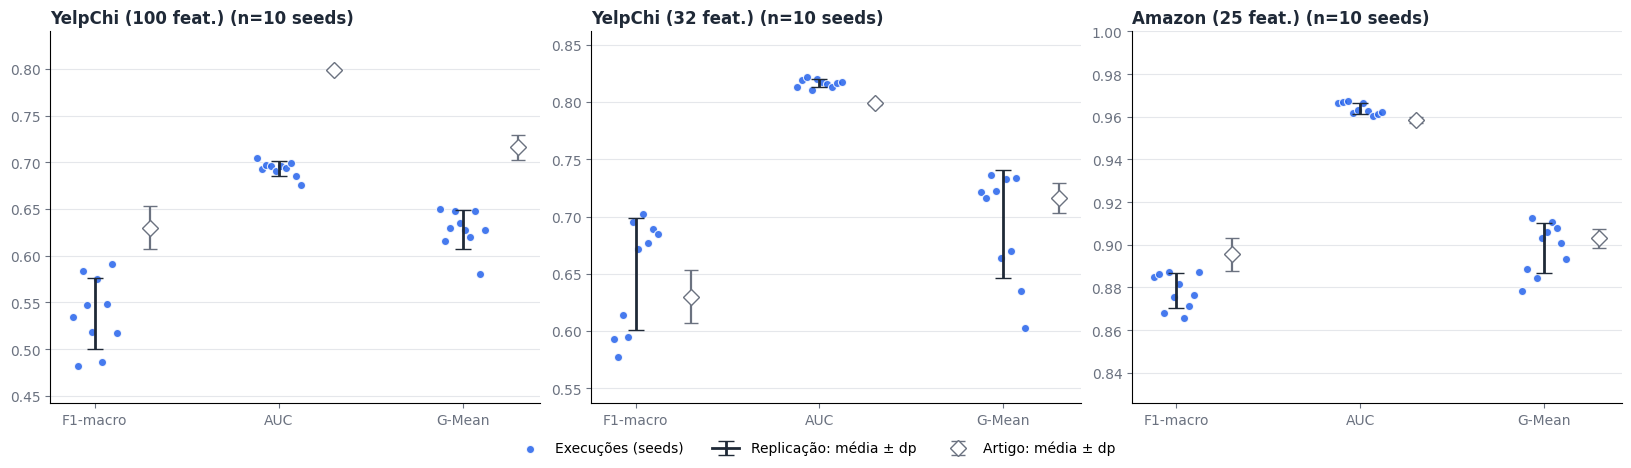

In [ ]:
INK, MUTED, BLUE = '#1f2937', '#6b7280', '#2563eb'
fig, axes = plt.subplots(1, len(DATASETS), figsize=(5.4 * len(DATASETS), 4.6), squeeze=False, constrained_layout=True)
for axis, key in zip(axes[0], DATASETS):
    sub = df[df['dataset'] == key]
    if sub.empty:
        axis.set_visible(False)
        continue
    shown = ['f1_macro', 'auc', 'g_mean']
    low, high = 1.0, 0.0
    for x, metric in enumerate(shown):
        values = sub[metric].to_numpy()
        jitter = np.linspace(-0.12, 0.12, len(values)) if len(values) > 1 else np.zeros(1)
        axis.scatter(x + jitter, values, s=34, color=BLUE, alpha=0.85, edgecolor='white', linewidth=0.8, zorder=3,
                     label='Execuções (seeds)' if x == 0 else None)
        mean = values.mean()
        std = values.std(ddof=1) if len(values) > 1 else 0.0
        axis.errorbar(x, mean, yerr=std, color=INK, capsize=6, linewidth=2, zorder=4, label='Replicação: média ± dp' if x == 0 else None)
        paper_mean, paper_std = PAPER[BASE[key]][metric]
        axis.errorbar(x + 0.3, paper_mean, yerr=paper_std, fmt='D', markersize=8, markerfacecolor='white', color=MUTED,
                      capsize=5, linewidth=1.6, zorder=3, label='Artigo: média ± dp' if x == 0 else None)
        low = min(low, values.min(), paper_mean - paper_std)
        high = max(high, values.max(), paper_mean + paper_std)
    axis.set_xticks(range(len(shown)))
    axis.set_xticklabels([LABELS[m] for m in shown], color=INK)
    axis.set_ylim(max(0, low - 0.04), min(1, high + 0.04))
    axis.set_title(f'{NAMES[key]} (n={len(sub)} seeds)', color=INK, loc='left', fontweight='bold')
    axis.grid(axis='y', color='#e5e7eb', linewidth=0.8, zorder=0)
    axis.spines[['top', 'right']].set_visible(False)
    axis.tick_params(colors=MUTED)
handles, labels = axes[0][0].get_legend_handles_labels()
fig.legend(handles, labels, loc='outside lower center', ncol=3, frameon=False, fontsize=10)
plt.show()

## 12. YelpChi: 32 × 100 features, seed a seed
Compara `yelp` (32 features) com `yelp100` (100 features) nas **mesmas seeds**, mesmo YAML, mesma partição, mesmo grafo e mesmos rótulos; só as features mudam. `Δ` é 100 − 32; `seeds em que 100 > 32` conta em quantas das seeds pareadas a versão de 100 features foi melhor.
O `p` é de um teste de Wilcoxon pareado e serve só como **indicação**: são poucas seeds, e a inicialização dos pesos não é a mesma entre as duas dimensões de entrada, então o pareamento por seed é aproximado. Se a diferença for pequena frente ao desvio padrão, a mudança de features sozinha não explica o desvio em relação ao artigo.

In [ ]:
from scipy.stats import wilcoxon

paired = None
if {'yelp', 'yelp100'} <= set(df['dataset']):
    small = df[df['dataset'] == 'yelp'].set_index('seed')
    large = df[df['dataset'] == 'yelp100'].set_index('seed')
    common = sorted(set(small.index) & set(large.index))
    if len(common) >= 3:
        paired_rows = []
        for metric, label in LABELS.items():
            a, b = small.loc[common, metric].to_numpy(), large.loc[common, metric].to_numpy()
            try:
                p_value = float(wilcoxon(b, a).pvalue)
            except ValueError:          # todas as diferenças são zero
                p_value = float('nan')
            paper_mean = PAPER['yelp'][metric][0]
            paired_rows.append({'métrica': label, 'seeds pareadas': len(common),
                                '32 feat. (média ± dp)': f'{a.mean():.4f} ± {a.std(ddof=1):.4f}',
                                '100 feat. (média ± dp)': f'{b.mean():.4f} ± {b.std(ddof=1):.4f}',
                                'artigo': f'{paper_mean:.4f}', 'Δ (100 − 32)': round(float((b - a).mean()), 4),
                                'seeds em que 100 > 32': int((b > a).sum()), 'p (Wilcoxon pareado)': round(p_value, 4)})
        paired = pd.DataFrame(paired_rows)
        display(paired)
    else:
        print('Seeds em comum insuficientes (<3) entre yelp e yelp100 para comparar.')
else:
    print("Esta comparação precisa de resultados de 'yelp' e 'yelp100'. Inclua os dois em DATASETS e execute os treinos.")

,métrica,seeds pareadas,32 feat. (média ± dp),100 feat. (média ± dp),artigo,Δ (100 − 32),seeds em que 100 > 32,p (Wilcoxon pareado)
0,F1-macro,10,0.6499 ± 0.0490,0.5384 ± 0.0382,0.6300,-0.1115,0,0.0020
1,AUC,10,0.8166 ± 0.0034,0.6932 ± 0.0079,0.7987,-0.1234,0,0.0020
2,G-Mean,10,0.6935 ± 0.0476,0.6281 ± 0.0206,0.7160,-0.0654,1,0.0039
3,F1-fraude,10,0.4513 ± 0.0315,0.3379 ± 0.0103,0.4344,-0.1134,0,0.0020
4,F1-benigno,10,0.8485 ± 0.0696,0.7390 ± 0.0703,0.8255,-0.1096,1,0.0039


## 13. Custo computacional
Soma só o tempo dos batches de treino que o próprio `main.py` imprime (não inclui validação, salvamento nem teste). O tempo depende da máquina que o Colab sorteou.

In [ ]:
timing = (df.groupby('dataset')
            .agg(n=('seed', 'count'), segundos_treino_medio=('train_seconds', 'mean'),
                 melhor_epoca_media=('best_epoch', 'mean'), dim_features=('feature_dim', 'first'))
            .round(1))
display(timing)

,n,segundos_treino_medio,melhor_epoca_media,dim_features
dataset,,,,
amazon,10,90.5,37.0,25
yelp,10,456.2,49.0,32
yelp100,10,611.7,11.5,100


## 14. Exportar relatório
Grava no Drive as tabelas, o gráfico e um manifesto (commit do código, versões, SHA-256 de cada arquivo de dados, impressão digital do grafo, origem dos dados, seeds, épocas) para que a replicação possa ser reproduzida e auditada.

In [ ]:
REPORT = RESULTS_ROOT / 'reports' / datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S')
REPORT.mkdir(parents=True, exist_ok=False)
df.to_csv(REPORT / 'results_per_seed.csv', index=False)
summary.drop(columns=['mean', 'std']).to_csv(REPORT / 'summary_vs_paper.csv', index=False)
if paired is not None:
    paired.to_csv(REPORT / 'yelp_32_vs_100_features.csv', index=False)
fig.savefig(REPORT / 'seeds_vs_paper.png', dpi=160)
write_json(REPORT / 'manifest.json', {
    'notebook_version': 'v3', 'created_utc': datetime.now(timezone.utc).isoformat(), 'repo_url': REPO_URL, 'commit': COMMIT,
    'local_changes': LOCAL_CHANGES, 'versions': VERSIONS, 'python': sys.version, 'platform': platform.platform(),
    'datasets': DATA_INFO,
    'dgfraud_source': {'commit': DGFRAUD_COMMIT, 'url': DGFRAUD_URL, 'zip_sha256_expected': DGFRAUD_ZIP_SHA256},
    'seeds': SEEDS, 'num_epochs_override': NUM_EPOCHS, 'quick_test': QUICK_TEST,
    'seeds_done': {d: int((df['dataset'] == d).sum()) for d in DATASETS}})
print('Relatório salvo em:', REPORT)

Relatório salvo em: /content/drive/MyDrive/PC_GNN_replicacao/reports/20261106_182300


## 15. Como ler o resultado
- **Compare tendências, não casas decimais.** Com 51 épocas (em vez de 100) e versões modernas de PyTorch/scikit-learn, diferenças de poucos pontos nas médias são esperadas. O que se espera replicar é o padrão: AUC e G-Mean bem mais altos na Amazon que no YelpChi, F1-fraude baixo no YelpChi (~0,43) e alto na Amazon (~0,81).
- **Features do YelpChi.** `yelp100` usa a dimensão que o artigo reporta; `yelp` usa a versão pública. A seção 12 mostra o efeito isolado dessa troca. Duas leituras possíveis: se `yelp100` ficar claramente mais perto do artigo, as features explicavam parte do desvio; se ficar parecido com `yelp`, o desvio vem de outro ponto (épocas, limiar de classificação, versões das bibliotecas). Lembre que o arquivo de 100 features é a melhor candidata encontrada, mas não está provado que seja idêntico ao dos autores.
- **Amazon.** Só existe a versão de 25 features; o artigo diz 100, mas nenhuma fonte com 100 foi encontrada (ver seção 4).
- **Divergências de dados** aparecem na tabela da seção 4 (coluna `features` e mensagens de atenção). A mensagem "features = 32, o artigo reporta 100" no `yelp` é esperada.
- **Época do melhor checkpoint.** Se `best_epoch` for 50 (a última validação) em quase todas as seeds, o treino de 51 épocas ainda não saturou. Foi o que ocorreu nos testes do YelpChi com 32 features. O artigo cita 100 épocas: rode com `NUM_EPOCHS = 100` e um `RESULTS_ROOT` diferente para não misturar as séries.
- **A partição é fixa** (`random_state=2`), então o desvio padrão reflete só a aleatoriedade do treino (inicialização e amostragem), não a escolha do split.
- **Fora do escopo:** baselines e ablações do artigo. Reproduzi-los exigiria implementar PC-GNN\P (sem o amostrador balanceado por rótulo) e PC-GNN\C (sem o amostrador de vizinhança), que não existem no repositório.